# Day6：两个智能体的 MAPPO 风格最小训练闭环

教师提供的分段练习，供 RedMoon 阅读、修改和复跑。
本次真正进行环境采样、两个局部 Actor 的 PPO 更新、集中式 V 的学习与冻结评估，
不再只给三条手工经历做一次更新。

环境是一局一步的“两盏灯配合”：每人只观察自己的灯，选择保持或翻转。
两盏灯最终相同，团队奖励为 2；不同则为 0，然后本局真正终止。
合作不是必须执行相同动作，而是共同实现正确结果。

使用两个独立 Actor 和一个集中式 V，按角色分别计算 PPO 概率比。
本环境一步终止，GAE 退化为 `reward - old_value`，价值目标就是 reward；
因此不重复实现 Day5 的一般长轨迹 GAE。本练习不实现 COMA、循环网络、
并行环境或 mini-batch，也不以单个种子证明算法性能。

## 1. 导入与本次配置

| 变量 | 含义 |
|---|---|
| `episodes_per_batch` | 两人共同采样多少个完整回合，不是每人各采一批 |
| `num_updates` | “共同采样一批，然后训练本批”的外层次数 |
| `update_epochs` | 本批最多进行几轮梯度更新 |
| `clip_eps` | 每个角色自己的新旧动作概率比的裁剪幅度 |
| `critic_coef` | Critic 损失在联合损失里的权重 |
| `entropy_coef` | 熵奖励权重；小幅鼓励保留探索 |
| `target_kl` | 任一角色的近似 KL 超过它，就停止本批后续更新 |
| `eval_episodes` | 参数冻结后，另外采样多少回合用于评估 |

每局只有第 0 步，当前奖励不再乘折扣。
极小网络使用 CPU；只调整本进程的 Windows 数值库兼容设置。

In [1]:
import os
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import itertools
import json
import math
import random
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

torch.set_num_threads(1)
seed = 7
episodes_per_batch, num_updates, update_epochs = 64, 120, 4
actor_lr, critic_lr = 0.03, 0.08
clip_eps, critic_coef, entropy_coef = 0.2, 0.5, 0.01
max_grad_norm, target_kl, eval_episodes = 0.5, 0.03, 500
print("PyTorch:", torch.__version__)
print("每批共同回合数 / 外层批数 / 每批最大优化轮数:",
      episodes_per_batch, num_updates, update_epochs)

PyTorch: 2.10.0+cu128
每批共同回合数 / 外层批数 / 每批最大优化轮数: 64 120 4


## 2. 环境：只看自己的灯，同时执行动作

灯的状态 `0=灭、1=亮`；动作 `0=保持、1=翻转`。
例如初始 `(0,1)`，联合动作 `(0,1)`，最后就是 `(0,0)`，奖励为 2。
两人动作不同，也能成功合作。

`bits` 保存两盏灯的状态。每个 Actor 只取自己的那一个数；
训练时 Critic 才能获得完整的两位状态。
`terminated=True` 表示本局任务真正结束，不存在这一步之后的未来奖励。

In [2]:
class TwoLightEnv:
    def __init__(self, seed):
        self.rng = random.Random(seed)
        self.bits = None
        self.finished = True
        self.reset_count = self.step_count = 0

    def reset(self, initial=None):
        # 默认独立、等概率生成两盏灯；initial 只用于逐状态评估和规则检查。
        self.bits = (tuple(initial) if initial is not None else
                     (self.rng.randrange(2), self.rng.randrange(2)))
        assert len(self.bits) == 2 and all(b in (0, 1) for b in self.bits)
        self.finished = False
        self.reset_count += 1
        return self.bits

    def step(self, actions):
        if self.finished:
            raise RuntimeError("本局已终止，先 reset 再执行动作")
        assert len(actions) == 2 and all(a in (0, 1) for a in actions)
        # XOR：保持时原样，翻转时 0/1 互换。
        final_bits = tuple(b ^ a for b, a in zip(self.bits, actions))
        reward = 2.0 if final_bits[0] == final_bits[1] else 0.0
        self.bits, self.finished = final_bits, True
        self.step_count += 1
        return final_bits, reward, True, {}

example_env = TwoLightEnv(seed)
print("初始:", example_env.reset((0, 1)))
print("执行保持/翻转:", example_env.step((0, 1)))

初始: (0, 1)
执行保持/翻转: ((0, 0), 2.0, True, {})


## 3. 局部输入与集中式输入

每个 Actor 用自己的灯状态 one-hot：灭 `[1,0]`、亮 `[0,1]`。
Critic 将完整初始状态编码为四维 one-hot：
`00 -> [1,0,0,0]`，`01 -> [0,1,0,0]`，`10 -> [0,0,1,0]`，`11 -> [0,0,0,1]`。
本环境中这四维确实代表完整状态，不将这一结论推广到所有观测拼接。

三个线性网络参数独立。两个 Actor 输出保持/翻转的得分；
Critic 输出当前联合策略的团队价值预测，不输入本局实际动作。
都初始化为零：动作概率为 0.5/0.5，Critic 预测为 0；
初始策略的真实平均回报为 1，不等于未训练 Critic 已输出 1。

In [3]:
def local_input(bit):
    return torch.eye(2)[bit].unsqueeze(0)  # (1, 2)，保留批次维。

def central_input(bits):
    index = bits[0] * 2 + bits[1]
    return torch.eye(4)[index].unsqueeze(0)  # (1, 4)，只来自初始状态。

class TeamModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.actors = nn.ModuleList([
            nn.Linear(2, 2, bias=False), nn.Linear(2, 2, bias=False)])
        self.critic = nn.Linear(4, 1, bias=False)
        for parameter in self.parameters():
            nn.init.zeros_(parameter)

def make_optimizer(model):
    return torch.optim.Adam([
        {"params": model.actors.parameters(), "lr": actor_lr},
        {"params": model.critic.parameters(), "lr": critic_lr},
    ])

## 4. 精确策略评价：枚举状态，不依赖幸运采样

四种初始状态等概率出现。给定一组状态，枚举四种联合动作，
把每种动作组合的概率乘以是否成功，就得到精确合作成功概率。
本例两名 Actor 独立采样，联合动作概率是两份概率的乘积；
这不表示训练时要把各角色 PPO 比值也乘起来。

`success_probability` 是当前策略的精确成功率；
`expected_return` 等于它乘 2；`true_values` 保存四种状态各自的真实策略价值。
这些只是评估，不送入训练作为答案或目标。

In [4]:
@torch.no_grad()
def policy_stats(model):
    probabilities = [
        Categorical(logits=actor(torch.eye(2))).probs
        for actor in model.actors]
    true_values = []
    for b0, b1 in itertools.product(range(2), repeat=2):
        success = 0.0
        for a0, a1 in itertools.product(range(2), repeat=2):
            if (b0 ^ a0) == (b1 ^ a1):
                success += float(probabilities[0][b0, a0] *
                                 probabilities[1][b1, a1])
        true_values.append(2 * success)
    predicted = model.critic(torch.eye(4)).squeeze(-1).tolist()
    expected = sum(true_values) / 4
    return {"success_probability": expected / 2,
            "expected_return": expected,
            "policy_0": probabilities[0].tolist(),
            "policy_1": probabilities[1].tolist(),
            "true_values": true_values, "predicted_values": predicted,
            "value_error": max(abs(a - b) for a, b in zip(predicted, true_values))}

print("初始化:", policy_stats(TeamModel()))

初始化: {'success_probability': 0.5, 'expected_return': 1.0, 'policy_0': [[0.5, 0.5], [0.5, 0.5]], 'policy_1': [[0.5, 0.5], [0.5, 0.5]], 'true_values': [1.0, 1.0, 1.0, 1.0], 'predicted_values': [0.0, 0.0, 0.0, 0.0], 'value_error': 1.0}


## 5. 联合 rollout：一行就是两人同一次配合

`collect_batch` 内没有 `optimizer.step()`。两个 Actor 的参数在整批采样期间不变。
每局各自取自己的观测、独立选动作，再将动作一起交给环境。

| 批次字段 | 形状 | 意义 |
|---|---|---|
| `obs_0`, `obs_1` | `[B,2]` | 两人当时的局部观测 |
| `central_states` | `[B,4]` | 同一局的初始全局状态，只供 Critic 使用 |
| `actions`, `old_log_probs` | `[B,2]` | 两人各自的实际动作及旧对数概率 |
| `rewards`, `old_values`, `terminated` | `[B]` | 一份团队奖励、价值快照、真正终止标记 |
| `initial_bits`, `final_bits` | `[B,2]` | 用于检查实际环境结果，不是 Actor 的额外输入 |

`B` 是共同回合数，不是共同回合数乘智能体人数。

In [5]:
@torch.no_grad()
def collect_batch(model, env, n_episodes=episodes_per_batch):
    fields = {name: [] for name in (
        "obs_0", "obs_1", "central_states", "actions", "old_log_probs",
        "rewards", "old_values", "terminated", "initial_bits", "final_bits")}
    for _ in range(n_episodes):
        bits = env.reset()
        local = [local_input(bits[i]) for i in range(2)]
        global_state = central_input(bits)
        distributions = [
            Categorical(logits=model.actors[i](local[i])) for i in range(2)]
        selected = [dist.sample() for dist in distributions]
        actions = tuple(int(action.item()) for action in selected)
        old_log_probs = [
            dist.log_prob(action).item()
            for dist, action in zip(distributions, selected)]
        old_value = model.critic(global_state).item()
        final_bits, reward, terminated, _ = env.step(actions)

        fields["obs_0"].append(local[0].squeeze(0))
        fields["obs_1"].append(local[1].squeeze(0))
        fields["central_states"].append(global_state.squeeze(0))
        fields["actions"].append(actions)
        fields["old_log_probs"].append(old_log_probs)
        fields["rewards"].append(reward)
        fields["old_values"].append(old_value)
        fields["terminated"].append(terminated)
        fields["initial_bits"].append(bits)
        fields["final_bits"].append(final_bits)
    batch = {}
    for name, entries in fields.items():
        if name in ("obs_0", "obs_1", "central_states"):
            batch[name] = torch.stack(entries)
        else:
            dtype = (torch.long if name in ("actions", "initial_bits", "final_bits")
                     else torch.bool if name == "terminated" else torch.float32)
            batch[name] = torch.tensor(entries, dtype=dtype)
    return batch

## 6. 本批目标：一步真正终止，未来价值为零

每条经历都真正终止，所以原始优势为 `rewards - old_values`，
Critic 目标为 `rewards`。这是 GAE 的终止单步特例，不是删除长任务里的 GAE。
本次不标准化优势，保留共同评分的原始数值与符号。

`demo_model` 只用于观察这一批数据，不是后面正式训练的模型。
旧概率、优势和目标都没有计算图；训练时重新前向获取当前输出的计算图。

In [6]:
@torch.no_grad()
def prepare_batch(batch):
    assert batch["terminated"].all(), "本函数只用于当前一步终止环境"
    batch["advantages"] = (batch["rewards"] - batch["old_values"]).clone()
    batch["targets"] = batch["rewards"].clone()
    return batch

torch.manual_seed(seed)
demo_model, demo_env = TeamModel(), TwoLightEnv(seed)
demo_before = {k: v.clone() for k, v in demo_model.state_dict().items()}
demo_batch = prepare_batch(collect_batch(demo_model, demo_env))
demo_after_collect = {k: v.clone() for k, v in demo_model.state_dict().items()}
print("initial actions final reward old_probs old_value advantage target")
for i in range(6):
    print(demo_batch["initial_bits"][i].tolist(),
          demo_batch["actions"][i].tolist(), demo_batch["final_bits"][i].tolist(),
          demo_batch["rewards"][i].item(),
          demo_batch["old_log_probs"][i].exp().tolist(),
          demo_batch["old_values"][i].item(),
          demo_batch["advantages"][i].item(), demo_batch["targets"][i].item())

initial actions final reward old_probs old_value advantage target
[1, 0] [0, 1] [1, 1] 2.0 [0.5, 0.5] 0.0 2.0 2.0
[1, 0] [1, 1] [0, 1] 0.0 [0.5, 0.5] 0.0 0.0 0.0
[0, 0] [0, 0] [0, 0] 2.0 [0.5, 0.5] 0.0 2.0 2.0
[1, 0] [0, 1] [1, 1] 2.0 [0.5, 0.5] 0.0 2.0 2.0
[0, 0] [1, 1] [1, 1] 2.0 [0.5, 0.5] 0.0 2.0 2.0
[0, 1] [1, 0] [1, 1] 2.0 [0.5, 0.5] 0.0 2.0 2.0


### 保存输出解读：一行经历怎样从灯的变化变成训练评分

以下解析于 **2026-10-10** 根据当前已保存的运行结果补充，没有重新训练或替换输出。保存输出中的 PyTorch 版本为 `2.10.0+cu128`；版本带 CUDA 后缀不等于这份代码已把模型放到 GPU。以后重新运行时，以下静态数字需要与新输出对照。

动作 0 是保持、动作 1 是翻转；灯 0 是灭、灯 1 是亮。看输出的前两行就能串起整个过程：

| 初始灯状态 | 两人实际动作 | 最终灯状态 | 团队奖励 | 旧价值 | 优势 | Critic 目标 |
|---|---|---|---:|---:|---:|---:|
| `[1, 0]` | `[0, 1]` | `[1, 1]` | 2 | 0 | 2 | 2 |
| `[1, 0]` | `[1, 1]` | `[0, 1]` | 0 | 0 | 0 | 0 |

第一行是亮灯保持、灭灯翻转，最终都亮，合作成功。第二行两人都翻转，但最终一灭一亮，合作失败。**动作相同不等于合作成功，动作不同也不等于失败**；这里的目标是最终两灯相同，灭、灭同样合法。

初始化 Critic 输出 0，所以本批 `advantage = reward - old_value`。失败行优势恰好为 0，并不是正评分；此时它没有直接的 Actor 优势项梯度。后续 Critic 预估提高后，奖励 0 的经历可以得到负优势。

`old_probs = [0.5, 0.5]` 是两名智能体各自实际动作的旧概率，不是一名智能体两个动作的完整概率表。本环境一步真正终止，目标就是当前奖励，没有终点后的 bootstrap。

## 7. 两个 Actor 的 PPO 损失，以及一个 Critic 的损失

第 `i` 个 Actor 只输入 `obs_i`，读取 `actions[:, i]` 和 `old_log_probs[:, i]`。
共享评分不等于混用动作，不等于把两个 PPO 比值相乘。

每人对本批经历取平均，再对两人的策略损失取平均。
Critic 用集中式状态预测价值，拟合固定目标；熵奖励单独加入总损失。
`values` 与 `targets` 都为 `[B]`，避免意外广播。
近似 KL 和 clip fraction 分角色计算，不把其中一个角色的大变化藏进总均值。

In [7]:
def compute_losses(model, batch):
    actor_losses, entropies, ratios, log_ratios = [], [], [], []
    for i in range(2):
        dist = Categorical(logits=model.actors[i](batch[f"obs_{i}"]))
        log_prob = dist.log_prob(batch["actions"][:, i])
        log_ratio = log_prob - batch["old_log_probs"][:, i]
        ratio = log_ratio.exp()
        raw = ratio * batch["advantages"]
        clipped = ratio.clamp(1 - clip_eps, 1 + clip_eps) * batch["advantages"]
        actor_losses.append(-torch.minimum(raw, clipped).mean())
        entropies.append(dist.entropy().mean())
        ratios.append(ratio)
        log_ratios.append(log_ratio)
    actor_loss = torch.stack(actor_losses).mean()
    values = model.critic(batch["central_states"]).squeeze(-1)
    assert values.shape == batch["targets"].shape
    critic_loss = (values - batch["targets"]).square().mean()
    entropy = torch.stack(entropies).mean()
    total_loss = actor_loss + critic_coef * critic_loss - entropy_coef * entropy
    with torch.no_grad():
        kls = [float(((r - 1) - lr).mean()) for r, lr in zip(ratios, log_ratios)]
        clips = [float(((r - 1).abs() > clip_eps).float().mean()) for r in ratios]
    metrics = {"actor_loss": actor_loss.item(), "critic_loss": critic_loss.item(),
               "entropy": entropy.item(), "kl_0": kls[0], "kl_1": kls[1],
               "clip_0": clips[0], "clip_1": clips[1]}
    parts = {"actor_loss": actor_loss, "critic_loss": critic_loss, "ratios": ratios}
    return total_loss, metrics, parts

## 8. 有限多轮更新：评分和分母不跟着网络刷新

每轮重新前向、清空梯度、反传，再执行一次参数更新。
本批的两人旧概率、旧价值、共同优势和 Critic 目标始终保持不变。
任一角色的近似 KL 超过阈值后，停止本批后续更新；这不是硬性概率约束。

一次 `optimizer.step()` 共同更新三组独立参数，不表示执行时要由一个中央策略选动作。
`clip_grad_norm_` 是梯度范数裁剪，与 PPO 的概率比裁剪不同。

In [8]:
def update_batch(model, optimizer, batch, kl_limit=target_kl):
    fixed_names = ("old_log_probs", "old_values", "advantages", "targets")
    snapshots = {name: batch[name].clone() for name in fixed_names}
    epoch_logs, stopped = [], False
    for epoch in range(update_epochs):
        loss, metrics, _ = compute_losses(model, batch)
        if max(metrics["kl_0"], metrics["kl_1"]) > kl_limit:
            stopped = True
            break
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()
        epoch_logs.append({"epoch": epoch + 1, **metrics})
    with torch.no_grad():
        _, final_metrics, _ = compute_losses(model, batch)
    assert all(torch.equal(batch[k], snapshots[k]) for k in fixed_names)
    return epoch_logs, final_metrics, stopped

demo_loss, demo_initial_metrics, demo_parts = compute_losses(demo_model, demo_batch)
demo_logs, demo_final_metrics, demo_stopped = update_batch(
    demo_model, make_optimizer(demo_model), demo_batch)
print("本批实际优化轮数:", len(demo_logs))
print("更新后两名角色的指标:", demo_final_metrics)

本批实际优化轮数: 4
更新后两名角色的指标: {'actor_loss': -0.8773326277732849, 'critic_loss': 1.2529083490371704, 'entropy': 0.6860020756721497, 'kl_0': 0.0071606384590268135, 'kl_1': 0.007036970928311348, 'clip_0': 0.0, 'clip_1': 0.0}


### 保存输出解读：演示批次更新后的指标

这一小节先在 `demo_model` 上演示一批的 4 次更新；后面的完整训练会重新初始化 `model`，不会沿用这份演示参数。

| 指标 | 保存值（约） | 在本代码中的含义 |
|---|---:|---|
| `actor_loss` | -0.877333 | 两个角色各自 PPO 裁剪损失的平均值；负号来自最大化目标转成最小化损失 |
| `critic_loss` | 1.252908 | 这一批价值预测相对固定奖励目标的 MSE |
| `entropy` | 0.686002 | 两人动作分布的平均熵，接近二动作均匀分布的 `ln(2) ≈ 0.693147` |
| `kl_0 / kl_1` | 0.007161 / 0.007037 | 当前策略相对本批旧策略的采样近似 KL |
| `clip_0 / clip_1` | 0 / 0 | 当前实际动作概率比超出 `[0.8, 1.2]` 的样本比例 |

损失为负不代表发生错误，也不直接等于平均奖励；低 KL 只说明策略相对本批旧策略变化较小。这里更新后 KL 低于门槛 0.03，代码记录了完整的 4 轮更新。`clip=0` 说明本批此时未越过概率比阈值，不能据此说 PPO 裁剪代码没有执行。

各轮使用同一批固定旧概率、旧价值、优势和目标，但每轮会重新计算当前网络输出。下一外层批次才重新采集经历。

## 9. 完整训练：重新共同采样，再训练这一批

这是正式训练入口，使用全新的三个网络与环境。
`total_episodes` 是共同回合数，`total_agent_actions` 才是两人动作次数之和。
本环境每局恰好一步，所以共同环境步数等于共同回合数。

曲线的 `sample_return` 来自更新前的真实经历，
`expected_return` 来自更新后策略的精确枚举评价；
两者时间点、含义不同，不要求逐批相等。

In [9]:
torch.manual_seed(seed)
model, train_env = TeamModel(), TwoLightEnv(seed)
optimizer = make_optimizer(model)
initial_parameters = {k: v.clone() for k, v in model.state_dict().items()}
initial_stats = policy_stats(model)
history = []
total_episodes = total_steps = total_optimizer_steps = 0
for update in range(num_updates):
    batch = prepare_batch(collect_batch(model, train_env))
    epoch_logs, metrics, stopped = update_batch(model, optimizer, batch)
    total_episodes += len(batch["rewards"])
    total_steps += len(batch["rewards"])
    total_optimizer_steps += len(epoch_logs)
    stats = policy_stats(model)
    history.append({"update": update + 1, **stats, **metrics,
                    "sample_return": batch["rewards"].mean().item(),
                    "optimizer_steps": len(epoch_logs), "stopped": stopped})
    if update == 0 or (update + 1) % 30 == 0:
        print(f'batch={update + 1:3d}, success={stats["success_probability"]:.4f}, '
              f'J={stats["expected_return"]:.4f}, '
              f'value_error={stats["value_error"]:.4f}, epochs={len(epoch_logs)}')
final_stats = policy_stats(model)
total_agent_actions = 2 * total_steps
print("共同回合数 / 环境步数 / 个体动作次数 / 参数更新次数:",
      total_episodes, total_steps, total_agent_actions, total_optimizer_steps)

batch=  1, success=0.5071, J=1.0143, value_error=0.6988, epochs=4
batch= 30, success=0.9791, J=1.9583, value_error=0.0500, epochs=4
batch= 60, success=0.9932, J=1.9865, value_error=0.0224, epochs=4
batch= 90, success=0.9955, J=1.9911, value_error=0.0102, epochs=4
batch=120, success=0.9969, J=1.9938, value_error=0.0237, epochs=4
共同回合数 / 环境步数 / 个体动作次数 / 参数更新次数: 7680 7680 15360 480


### 保存输出解读：训练量、精确成功率和价值误差

| 训练批次 | 更新后精确合作概率 | 更新后期望回报 J | `value_error` |
|---:|---:|---:|---:|
| 初始化 | 0.5000 | 1.0000 | 1.0000 |
| 1 | 0.5071 | 1.0143 | 0.6988 |
| 30 | 0.9791 | 1.9583 | 0.0500 |
| 60 | 0.9932 | 1.9865 | 0.0224 |
| 90 | 0.9955 | 1.9911 | 0.0102 |
| 120 | 0.9969 | 1.9938 | 0.0237 |

这里打印的 `success` 不是本批 64 局的成功比例，而是枚举四种初始状态和所有联合动作得到的**当前策略精确成功概率**。每次成功奖励 2、失败奖励 0，所以 `J = 2 × success`；最终精确值为 `0.9969121259` 和 `1.9938242517`。

`value_error` 的定义是：

```python
max(abs(predicted - true) for predicted, true in zip(predicted_values, true_values))
```

它是四个状态中的**最大绝对价值误差**，不是 `critic_loss` 的 MSE。第 90 批到第 120 批，策略成功率继续提高，但该误差从 0.0102 回升到 0.0237；说明策略改善与 Critic 每一步都更准确不是一回事。Critic 用采样奖励训练，而当前策略的真实价值也随策略改变。

训练计数分别是 `120 × 64 = 7680` 个共同回合，每局一步，所以也是 7680 个环境步；每步两人各行动一次，共 `15360` 个体动作；每批实际更新 4 次，共 `120 × 4 = 480` 次优化器更新。**480 次更新不等于 480 局，两个角色也不把一局算成两局。**这些计数属于正式训练循环，不包含前面的演示和后面的冻结评估。

## 10. 分散执行与冻结评估：不调用 Critic

执行函数只接收 `actors` 与各自局部观测，不接收集中式 Critic。
两人可以不执行相同动作，只要最终灯的状态相同就成功。
采样评估保留随机性；贪心评估逐一检查 00、01、10、11 四种初始状态。

前向钩子记录 Critic 的真实调用次数；评估后额外调用一次用于校准计数器。
另用评估种子，核对评估前后所有参数完全不变。

In [10]:
@torch.no_grad()
def choose_local_action(actor, own_bit, greedy=False):
    logits = actor(local_input(own_bit))
    action = (logits.argmax(dim=-1) if greedy else
              Categorical(logits=logits).sample())
    return int(action.item())

@torch.no_grad()
def decentralized_actions(actors, bits, greedy=False):
    return tuple(choose_local_action(actors[i], bits[i], greedy) for i in range(2))

@torch.no_grad()
def evaluate_episode(actors, env, greedy=False, initial=None):
    bits = env.reset(initial)
    actions = decentralized_actions(actors, bits, greedy)
    final_bits, reward, terminated, _ = env.step(actions)
    return {"initial": bits, "actions": actions, "final": final_bits,
            "reward": reward, "terminated": terminated}

model.eval()
before_eval = {k: v.clone() for k, v in model.state_dict().items()}
torch.manual_seed(2026)
eval_env, critic_calls = TwoLightEnv(2026), []
handle = model.critic.register_forward_hook(
    lambda module, inputs, output: critic_calls.append("called"))
try:
    eval_results = [evaluate_episode(model.actors, eval_env)
                    for _ in range(eval_episodes)]
    greedy_results = [evaluate_episode(model.actors, eval_env, True, bits)
                      for bits in itertools.product(range(2), repeat=2)]
    execution_critic_calls = len(critic_calls)
    with torch.no_grad():
        model.critic(torch.eye(4))
    calibration_calls = len(critic_calls)
finally:
    handle.remove()
eval_successes = sum(row["reward"] == 2 for row in eval_results)
eval_mean = sum(row["reward"] for row in eval_results) / eval_episodes
print("精确成功概率:", initial_stats["success_probability"], "->",
      final_stats["success_probability"])
print("冻结采样成功回合:", eval_successes, "/", eval_episodes)
print("冻结采样平均回报:", eval_mean)
print("初始 -> 各自动作 -> 最终 -> 团队奖励 -> 真正终止")
for row in greedy_results:
    print(row["initial"], "->", row["actions"], "->", row["final"],
          "->", row["reward"], "->", row["terminated"])
print("执行时 Critic 调用 / 校准调用:", execution_critic_calls, calibration_calls)

精确成功概率: 0.5 -> 0.9969121258718587
冻结采样成功回合: 496 / 500
冻结采样平均回报: 1.984
初始 -> 各自动作 -> 最终 -> 团队奖励 -> 真正终止
(0, 0) -> (1, 1) -> (1, 1) -> 2.0 -> True
(0, 1) -> (1, 0) -> (1, 1) -> 2.0 -> True
(1, 0) -> (0, 1) -> (1, 1) -> 2.0 -> True
(1, 1) -> (0, 0) -> (1, 1) -> 2.0 -> True
执行时 Critic 调用 / 校准调用: 0 1


### 保存输出解读：99.69%、99.2% 和四条全成功轨迹为什么不矛盾

**精确概率**为 `0.9969121259 ≈ 99.69%`：对已冻结策略的动作分布做枚举计算。**随机采样评估**为 `496 / 500 = 99.2%`：真实运行 500 个新回合，其中 4 次失败。有限随机采样不必刚好等于精确概率；采样平均回报 `1.984 = 2 × 496 / 500` 与成功次数一致。

**贪心评估**改为每次取概率最大的动作，逐一检查四种初始状态：

| 初始灯状态 | 动作（0 保持 / 1 翻转） | 最终灯状态 | 奖励 | 真正终止 |
|---|---|---|---:|---|
| `[0, 0]` | `[1, 1]` | `[1, 1]` | 2 | 是 |
| `[0, 1]` | `[1, 0]` | `[1, 1]` | 2 | 是 |
| `[1, 0]` | `[0, 1]` | `[1, 1]` | 2 | 是 |
| `[1, 1]` | `[0, 0]` | `[1, 1]` | 2 | 是 |

当前学出的局部规则是“自己的灯灭就翻转、亮就保持”，使两灯都亮。四条贪心轨迹全成功并不意味着随机策略成功率恰好为 100%：随机策略仍给非贪心动作很小的概率。

冻结评估没有更新参数，选动作时 Critic 调用为 0；之后人为调用一次作为计数器校准，计数变为 1。训练时集中式价值预测参与学习，执行时两人各自只看自己的灯，这就是本例实际验证的 CTDE 分工。

## 11. 训练图：合作结果、各自策略与价值预测

第一幅显示精确合作概率，第二幅区分实际采样回报和精确期望。
第三幅画两名 Actor 在“自己的灯灭/亮”两种输入下选择翻转的概率。
第四幅把四种集中状态的价值预测与当前真实策略价值直接对照。

四条策略曲线可能学会“全部变灭”或“全部变亮”，两种约定都合法。
判断结果是否合作成功，不能要求两人动作编号一致。
图中没有画反事实贡献，不能拿它证明 COMA 或集中式 Critic 的比较优势。

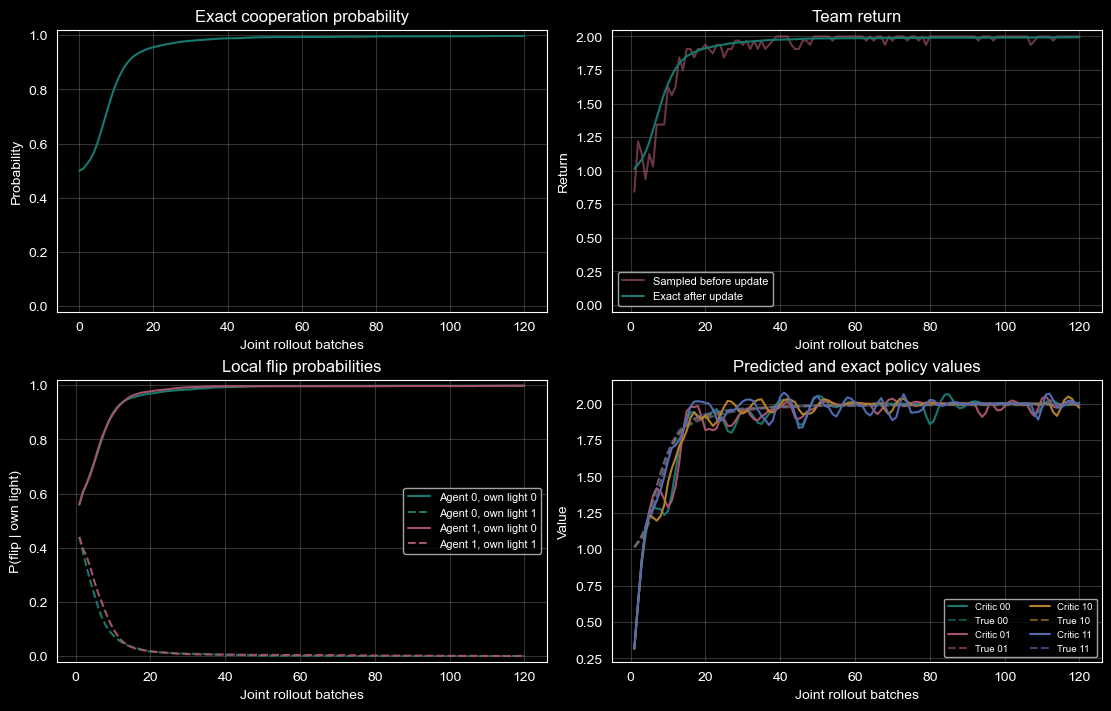

In [11]:
updates = [row["update"] for row in history]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
axes[0, 0].plot([0] + updates, [initial_stats["success_probability"]] +
               [row["success_probability"] for row in history], color="#16796f")
axes[0, 0].set(title="Exact cooperation probability",
               xlabel="Joint rollout batches", ylabel="Probability", ylim=(-.02, 1.02))
axes[0, 1].plot(updates, [row["sample_return"] for row in history],
               label="Sampled before update", color="#a4536b", alpha=.65)
axes[0, 1].plot(updates, [row["expected_return"] for row in history],
               label="Exact after update", color="#16796f")
axes[0, 1].set(title="Team return", xlabel="Joint rollout batches",
               ylabel="Return", ylim=(-.05, 2.05))
axes[0, 1].legend(fontsize=8)
for i, color in [(0, "#16796f"), (1, "#a4536b")]:
    for bit, style in [(0, "-"), (1, "--")]:
        axes[1, 0].plot(updates, [row[f"policy_{i}"][bit][1] for row in history],
                        style, color=color, label=f"Agent {i}, own light {bit}")
axes[1, 0].set(title="Local flip probabilities", xlabel="Joint rollout batches",
               ylabel="P(flip | own light)", ylim=(-.02, 1.02))
axes[1, 0].legend(fontsize=8)
for state, color in enumerate(["#16796f", "#a4536b", "#b78027", "#526ab2"]):
    axes[1, 1].plot(updates, [row["predicted_values"][state] for row in history],
                    color=color, label=f"Critic {state:02b}")
    axes[1, 1].plot(updates, [row["true_values"][state] for row in history],
                    "--", color=color, alpha=.65, label=f"True {state:02b}")
axes[1, 1].set(title="Predicted and exact policy values",
               xlabel="Joint rollout batches", ylabel="Value")
axes[1, 1].legend(fontsize=7, ncol=2)
for ax in axes.flat:
    ax.grid(alpha=.2)
plt.show()

### 保存图像解读：四个面板要和指标定义一起看

**左上：精确合作概率。**曲线从 0.5 向 1 靠近，最终约为 0.9969；横轴是一批新的联合 rollout，不是单局或某一次优化器更新。

**右上：团队回报。**粉色线是每批更新前采集的 64 局平均奖励，绿色线是更新后策略的精确期望。两条线既有有限采样与枚举的区别，也有更新前与更新后的时间区别，不能要求每个批次完全重合。后期偶尔采到失败经历，粉色线会回落，不代表参数一定退化。

**左下：局部翻转概率。**实线对应自己的灯为 0，接近 1；虚线对应自己的灯为 1，接近 0。最终 Actor 0 灭时翻转概率约为 0.997801、亮时保持概率约为 0.999000；Actor 1 对应约为 0.998049、0.998964。这不是“不管看见什么都翻转”，而是根据局部观测采用相反动作。

**右下：Critic 预测与精确策略价值。**同色实线是 Critic，虚线是该初始状态下按当前策略枚举得到的期望回报，不是每局实际奖励，也不是另一个目标网络。

| 初始状态 | 精确策略价值 | Critic 预测 | 绝对误差（约） |
|---|---:|---:|---:|
| 00 | 1.991718 | 2.005776 | 0.014059 |
| 01 | 1.993540 | 1.992540 | 0.001000 |
| 10 | 1.994107 | 1.970361 | 0.023746 |
| 11 | 1.995933 | 1.990280 | 0.005653 |

最大误差出现在 10 状态，正是末尾 `value_error ≈ 0.023746`。00 状态预测略高于奖励上限 2，是未限制输出范围的 Critic 的小幅估计偏差，不是环境发了超过 2 的奖励。

末尾摘要还记录 `clip_fraction_max = 0.140625`，表示本次历史记录中，两名角色的概率比越界比例最大值约为 14.06%；它不是成功率，也不等于所有这些样本的裁剪项都产生了零梯度。**56 项检查**验证训练与评估的数据、参数和接口对应，合作结果仍应看精确概率、冻结评估和完整轨迹，不能单看损失或检查数。

## 12. 自动检查：环境规则与信息/梯度对应

穷举四种初始状态与四种联合动作，直接检查真实 step 结果。
再检查一条批次里的初始状态、局部观测、集中状态、动作、最终状态和奖励
是否对应同一次交互。旧概率与评分不带梯度，当前两个 Actor 与 Critic 有梯度。

In [12]:
checks = []
def check(name, condition):
    assert condition, name
    checks.append(name)

rule_env, rules_ok = TwoLightEnv(0), True
for bits in itertools.product(range(2), repeat=2):
    for actions in itertools.product(range(2), repeat=2):
        rule_env.reset(bits)
        final_bits, reward, term, _ = rule_env.step(actions)
        expected = tuple(b ^ a for b, a in zip(bits, actions))
        rules_ok &= final_bits == expected and term
        rules_ok &= reward == (2.0 if expected[0] == expected[1] else 0.0)
check("all sixteen state-action transitions", rules_ok)
check("initial exact cooperation probability", initial_stats["success_probability"] == .5)
check("initial actual critic is zero", initial_stats["predicted_values"] == [0.] * 4)
check("collection does not train parameters", all(
    torch.equal(demo_before[k], v) for k, v in demo_after_collect.items()))
check("one shared batch of complete episodes", demo_batch["rewards"].shape == (episodes_per_batch,))
check("two local observation shapes",
      demo_batch["obs_0"].shape == demo_batch["obs_1"].shape == (episodes_per_batch, 2))
check("central state shape", demo_batch["central_states"].shape == (episodes_per_batch, 4))
check("two actual actions and two old probabilities",
      demo_batch["actions"].shape == demo_batch["old_log_probs"].shape == (episodes_per_batch, 2))
check("all sampled episodes truly terminate", demo_batch["terminated"].all())
check("local observations match same-row initial bits", all(
    torch.equal(demo_batch[f"obs_{i}"].argmax(-1), demo_batch["initial_bits"][:, i])
    for i in range(2)))
check("central input matches initial not final state", torch.equal(
    demo_batch["central_states"].argmax(-1),
    demo_batch["initial_bits"][:, 0] * 2 + demo_batch["initial_bits"][:, 1]))
check("actual actions produce saved final bits", torch.equal(
    demo_batch["initial_bits"] ^ demo_batch["actions"], demo_batch["final_bits"]))
check("shared rewards are not doubled", torch.equal(
    demo_batch["rewards"],
    torch.where(demo_batch["final_bits"][:, 0] == demo_batch["final_bits"][:, 1], 2., 0.)))
check("old snapshots and targets have no gradients", all(
    not demo_batch[name].requires_grad
    for name in ("old_log_probs", "old_values", "advantages", "targets")))
check("single terminal advantage", torch.equal(
    demo_batch["advantages"], demo_batch["rewards"] - demo_batch["old_values"]))
check("critic target keeps return scale", torch.equal(demo_batch["targets"], demo_batch["rewards"]))

## 13. 自动检查：角色概率比、裁剪与参数更新

额外构造不同的两个策略，故意让 AA 样本的概率比变为 1.2 与 0.8，
检查没有混成一个联合比值。四种 clip 分支用标量与梯度直接核对。
最后检查整行重排、不沿评分训练 Critic、非零梯度和真实参数变化。

In [13]:
ratio_model = TeamModel()
with torch.no_grad():
    ratio_model.actors[0].weight.copy_(torch.tensor([[.6, .6], [.4, .4]]).log())
    ratio_model.actors[1].weight.copy_(torch.tensor([[.4, .4], [.6, .6]]).log())
ratio_batch = {k: v[:1].clone() for k, v in demo_batch.items()}
ratio_batch["actions"].zero_()
_, _, ratio_parts = compute_losses(ratio_model, ratio_batch)
check("agent 0 uses its own probability ratio",
      math.isclose(ratio_parts["ratios"][0].item(), 1.2, abs_tol=1e-6))
check("agent 1 uses its own probability ratio",
      math.isclose(ratio_parts["ratios"][1].item(), .8, abs_tol=1e-6))
for ratio, advantage, objective, gradient in [
        (1.4, .4, .48, 0.), (.6, .4, .24, -.4),
        (.6, -.4, -.32, 0.), (1.4, -.4, -.56, .4)]:
    r = torch.tensor(ratio, dtype=torch.float64, requires_grad=True)
    value = torch.minimum(r * advantage, r.clamp(.8, 1.2) * advantage)
    (-value).backward()
    check(f"clip value {ratio}/{advantage}", math.isclose(value.item(), objective, abs_tol=1e-12))
    check(f"clip gradient {ratio}/{advantage}", math.isclose(r.grad.item(), gradient, abs_tol=1e-12))

gradient_model = TeamModel()
gradient_loss, _, parts = compute_losses(gradient_model, demo_batch)
actor_to_critic = torch.autograd.grad(
    parts["actor_loss"], tuple(gradient_model.critic.parameters()),
    allow_unused=True, retain_graph=True)
check("fixed actor scores do not train critic", all(g is None for g in actor_to_critic))
gradient_loss.backward()
for name, parameter in gradient_model.named_parameters():
    check(name + " receives a nonzero gradient", parameter.grad.abs().sum().item() > 0)
for name, parameter in model.state_dict().items():
    check(name + " actually changed during training",
          not torch.equal(initial_parameters[name], parameter))
order = torch.arange(episodes_per_batch - 1, -1, -1)
loss_a, _, _ = compute_losses(demo_model, demo_batch)
loss_b, _, _ = compute_losses(demo_model, {k: v[order] for k, v in demo_batch.items()})
check("whole-row permutation preserves loss", torch.allclose(loss_a, loss_b, atol=1e-6))
gate_model = TeamModel()
gate_logs, _, gate_stopped = update_batch(
    gate_model, make_optimizer(gate_model), demo_batch, kl_limit=1e-8)
check("KL gate stops further updates", gate_stopped and len(gate_logs) == 1)

## 14. 自动检查：完整训练与分散执行

训练结果检查针对这份默认配置，不是任意种子的收敛保证。
评估必须真的进入环境、走到真正终止，且不调用 Critic、不改参数。
四种初始状态都检查，避免只展示一条碰巧成功的轨迹。

In [14]:
check("all outer training batches recorded", len(history) == num_updates)
check("fresh complete episodes per batch",
      total_episodes == num_updates * episodes_per_batch)
check("one environment step per complete episode",
      total_steps == train_env.step_count == train_env.reset_count == total_episodes)
check("agent actions counted separately", total_agent_actions == 2 * total_episodes)
check("bounded optimizer updates", all(0 < r["optimizer_steps"] <= update_epochs for r in history))
check("all three models have finite parameters",
      all(torch.isfinite(p).all() for p in model.parameters()))
check("all recorded training metrics finite", all(
    math.isfinite(row[k]) for row in history
    for k in ("actor_loss", "critic_loss", "entropy", "kl_0", "kl_1")))
check("exact cooperation improves above .95", final_stats["success_probability"] > .95)
check("critic tracks all four current policy values", final_stats["value_error"] < .15)
check("separate frozen evaluation episodes", len(eval_results) == eval_episodes)
check("evaluation parameters unchanged", all(
    torch.equal(before_eval[k], v) for k, v in model.state_dict().items()))
check("execution makes no critic calls", execution_critic_calls == 0)
check("critic counter is calibrated", calibration_calls == 1)
check("all evaluation episodes truly terminate",
      all(row["terminated"] for row in eval_results + greedy_results))
check("greedy evaluation covers all initial states",
      {row["initial"] for row in greedy_results} == set(itertools.product(range(2), repeat=2)))
check("all four greedy paths achieve cooperation",
      all(row["reward"] == 2 and row["final"][0] == row["final"][1]
          for row in greedy_results))
check("sample success rate above .90", eval_successes / eval_episodes > .90)
check("sample return matches team success count",
      math.isclose(eval_mean, 2 * eval_successes / eval_episodes))
check("sample mean close to exact expectation",
      abs(eval_mean - final_stats["expected_return"]) < .12)
captured_inputs = [[], []]
handles = [actor.register_forward_pre_hook(
    lambda module, args, i=i: captured_inputs[i].append(args[0].clone()))
    for i, actor in enumerate(model.actors)]
try:
    decentralized_actions(model.actors, (0, 0), greedy=True)
    decentralized_actions(model.actors, (0, 1), greedy=True)
finally:
    for handle in handles:
        handle.remove()
check("changing teammate input leaves actor 0 input unchanged",
      torch.equal(captured_inputs[0][0], captured_inputs[0][1]))
check("teammate input intervention actually changes actor 1 input",
      not torch.equal(captured_inputs[1][0], captured_inputs[1][1]))
print(f"PASS {len(checks)} checks")
result = {"checks": checks, "initial": initial_stats, "final": final_stats,
          "episodes": total_episodes, "environment_steps": total_steps,
          "agent_actions": total_agent_actions, "optimizer_steps": total_optimizer_steps,
          "evaluation_successes": eval_successes, "evaluation_count": eval_episodes,
          "evaluation_mean": eval_mean, "greedy_paths": greedy_results,
          "execution_critic_calls": execution_critic_calls,
          "clip_fraction_max": max(max(row["clip_0"], row["clip_1"]) for row in history)}
print("RESULT_JSON=" + json.dumps(result, ensure_ascii=False))

PASS 56 checks
RESULT_JSON={"checks": ["all sixteen state-action transitions", "initial exact cooperation probability", "initial actual critic is zero", "collection does not train parameters", "one shared batch of complete episodes", "two local observation shapes", "central state shape", "two actual actions and two old probabilities", "all sampled episodes truly terminate", "local observations match same-row initial bits", "central input matches initial not final state", "actual actions produce saved final bits", "shared rewards are not doubled", "old snapshots and targets have no gradients", "single terminal advantage", "critic target keeps return scale", "agent 0 uses its own probability ratio", "agent 1 uses its own probability ratio", "clip value 1.4/0.4", "clip gradient 1.4/0.4", "clip value 0.6/0.4", "clip gradient 0.6/0.4", "clip value 0.6/-0.4", "clip gradient 0.6/-0.4", "clip value 1.4/-0.4", "clip gradient 1.4/-0.4", "fixed actor scores do not train critic", "actors.0.weight 

## 参考与范围

- Yu 等，The Surprising Effectiveness of PPO in Cooperative Multi-Agent Games，
  第 3.1--3.3 节：局部策略、集中式价值、共享奖励与 MAPPO/IPPO。
- 作者实现 `marlbenchmark/on-policy`，`R_MAPPO.ppo_update` 与 `train`：
  各角色实际动作的旧概率、PPO 裁剪及有限更新。
- PyTorch 2.11：Categorical、no_grad、Adam 与 clip_grad_norm_。

本练习用本项目已有的独立线性网络、全批更新和一步终止环境，
接成 MAPPO 风格最小闭环，不照搬完整 benchmark 工程。
集中式状态 V 提供共同评分，没有实现 COMA 的反事实 Q 或个体贡献估计。
两种配合约定都合法；一个配置的结果不证明集中式 Critic 相比 IPPO 更优。